# Candidate Validation

This notebook performs **independent evidence checking** for the highest-ranked AML screening candidates produced by Notebook 09.

The purpose is not to prove that the model predictions are correct. Instead, the notebook asks whether each predicted drug–target candidate already has support in independent public resources.

Four evidence sources are used:

- **ChEMBL** — experimentally reported drug–target bioactivity
- **PubMed** — published AML and drug–target literature
- **ClinicalTrials.gov** — human clinical studies involving AML
- **openFDA drug labels** — whether current product labeling contains an AML indication signal

The notebook validates the **Top-20 unique drug candidates** from the AML screening stage and keeps the original predicted target for each drug.

The final interpretation is deliberately conservative. A candidate is never called clinically effective simply because it receives a high model score or because one external database contains a record.

## Notebook workflow

```text
Notebook 09 outputs
      │
      ├── aml_top20_unique_drug_candidates.csv
      ├── candidate_drugs.csv
      └── aml_targets.csv
      │
      ▼
Top-20 predicted drug → AML target pairs
      │
      ├──────────────────────────────────────────────┐
      │                 │              │             │
      ▼                 ▼              ▼             ▼
   ChEMBL            PubMed      ClinicalTrials   openFDA
      │                 │              │             │
drug-target       AML papers      AML trials     AML label text
bioactivity       target papers
      │                 │              │             │
      └─────────────────┴──────────────┴─────────────┘
                             ▼
                    Evidence summary
                             │
                             ▼
                 Conservative category
                             │
         ┌───────────────────┼────────────────────┐
         ▼                   ▼                    ▼
 Known AML signal      Investigated /       Prediction-led
 / positive control    literature support   limited evidence
                             │
                             ▼
               Save final validation table
```

The validation resources are independent of the DAVIS training labels and are therefore used only after model screening.

In [3]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False,
)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = (
    "https://github.com/"
    "Thebluesky303/"
    "msc-dissertation-drug-repurposing.git"
)

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path(
    "/content/final-msc-dissertation-drug-repurposing"
)

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/"
    "final-msc-dissertation-drug-repurposing"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT / "results"
)


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in result_folders:
    (
        DRIVE_RESULTS / folder_name
    ).mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get(
    "colab-dissertation"
)

if not token:
    raise ValueError(
        "GITHUB_TOKEN was not found in Colab Secrets."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_auth = (
    f"AUTHORIZATION: basic {auth}"
)


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (
    REPO_DIR / ".git"
).exists():

    print(
        "Cloning repository..."
    )

    subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader={git_auth}",
            "clone",
            "--branch",
            BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    print(
        "Repository already exists."
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "fetch",
            "origin",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "switch",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "pull",
            "--ff-only",
            "origin",
            BRANCH,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = (
    REPO_DIR / "results"
)

if LOCAL_RESULTS.is_symlink():

    current_target = (
        LOCAL_RESULTS.resolve()
    )

    if current_target != (
        DRIVE_RESULTS.resolve()
    ):
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():

    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():

        destination = (
            DRIVE_RESULTS
            / item.name
        )

        if item.is_dir():

            shutil.copytree(
                item,
                destination,
                dirs_exist_ok=True,
            )

        else:

            shutil.copy2(
                item,
                destination,
            )

    shutil.rmtree(
        LOCAL_RESULTS
    )


if not LOCAL_RESULTS.exists():

    os.symlink(
        DRIVE_RESULTS,
        LOCAL_RESULTS,
        target_is_directory=True,
    )


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(
    REPO_DIR
)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(
    [
        "git",
        "branch",
        "--show-current",
    ],
    text=True,
).strip()

commit = subprocess.check_output(
    [
        "git",
        "log",
        "-1",
        "--oneline",
    ],
    text=True,
).strip()


print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print(
    "Repository:",
    REPO_DIR,
)

print(
    "Branch:",
    branch,
)

print(
    "Commit:",
    commit,
)

print(
    "Results saved to Drive:",
    LOCAL_RESULTS.resolve(),
)

print(
    "CUDA available:",
    torch.cuda.is_available(),
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")



Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 2924c26 Created using Colab
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: False
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 89.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 107.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 4.8 MB/s eta 0:00:00
Project requirements installed.
PyTorch: 2.11.0+cpu


# Part A — Setup

## 1. Imports

In [4]:
import json
import re
import sys
import time

from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from IPython.display import display
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

## 2. Locate the project folder

In [5]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")

    if content_dir.exists():
        candidates.extend(
            path.parent
            for path in content_dir.glob("*/config.py")
        )

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "results").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Run this notebook from the final_aml_gnn_dta project."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Result folders and validation settings

In [6]:
from config import (
    AML_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    RESULTS_DIR,
)

VALIDATION_DIR = (
    RESULTS_DIR
    / "validation"
)

VALIDATION_CACHE_DIR = (
    RESULTS_DIR
    / "validation_cache"
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

VALIDATION_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TOP_N = 20

PUBMED_RETMAX = 5
CLINICAL_TRIAL_SAMPLE_SIZE = 10

REQUEST_DELAY = 0.20

RETRIEVAL_DATE = datetime.now(
    timezone.utc
).date().isoformat()

print("Validation folder:", VALIDATION_DIR)
print("Cache folder:", VALIDATION_CACHE_DIR)
print("Retrieval date:", RETRIEVAL_DATE)

Validation folder: /content/final-msc-dissertation-drug-repurposing/results/validation
Cache folder: /content/final-msc-dissertation-drug-repurposing/results/validation_cache
Retrieval date: 2026-08-14


## 4. Independent evidence APIs

The notebook uses documented public REST interfaces:

- ChEMBL Web Services
- NCBI Entrez E-utilities for PubMed
- ClinicalTrials.gov API v2
- openFDA drug product labeling API

All query results are cached locally so a disconnected Colab session can resume without repeating completed requests.

In [7]:
CHEMBL_API_BASE = (
    "https://www.ebi.ac.uk/chembl/api/data"
)

NCBI_EUTILS_BASE = (
    "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"
)

CLINICALTRIALS_API_BASE = (
    "https://clinicaltrials.gov/api/v2"
)

OPENFDA_LABEL_API = (
    "https://api.fda.gov/drug/label.json"
)

print("ChEMBL:", CHEMBL_API_BASE)
print("NCBI E-utilities:", NCBI_EUTILS_BASE)
print("ClinicalTrials.gov:", CLINICALTRIALS_API_BASE)
print("openFDA label API:", OPENFDA_LABEL_API)

ChEMBL: https://www.ebi.ac.uk/chembl/api/data
NCBI E-utilities: https://eutils.ncbi.nlm.nih.gov/entrez/eutils
ClinicalTrials.gov: https://clinicaltrials.gov/api/v2
openFDA label API: https://api.fda.gov/drug/label.json


## 5. Reusable HTTP session

In [8]:
retry_policy = Retry(
    total=5,
    connect=5,
    read=5,
    backoff_factor=0.5,
    status_forcelist=[
        429,
        500,
        502,
        503,
        504,
    ],
    allowed_methods=["GET"],
)

session = requests.Session()

adapter = HTTPAdapter(
    max_retries=retry_policy
)

session.mount(
    "https://",
    adapter,
)

session.headers.update(
    {
        "User-Agent": (
            "MSc-AML-GNN-DTA-Dissertation/1.0 "
            "(academic research)"
        )
    }
)

print("HTTP session ready.")

HTTP session ready.


# Part B — Load the Top-20 AML candidates

## 6. Load Notebook 09 outputs

In [12]:
import pandas as pd
import os
from pathlib import Path

# Define paths based on where the files actually exist in your Drive
TOP_CANDIDATES_PATH = (
    PREDICTIONS_DIR
    / "aml_top20_unique_drug_candidates.csv"
)

CANDIDATE_DRUGS_PATH = Path(
    '/content/drive/MyDrive/final-msc-dissertation-drug-repurposing/data/raw/aml/candidate_drugs.csv'
)

AML_TARGETS_PATH = Path(
    '/content/drive/MyDrive/final-msc-dissertation-drug-repurposing/data/raw/aml/aml_targets.csv'
)

required_files = [
    TOP_CANDIDATES_PATH,
    CANDIDATE_DRUGS_PATH,
    AML_TARGETS_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required files are missing from the specified paths: "
        + ", ".join(
            str(path)
            for path in missing_files
        )
    )

top_candidates_df = pd.read_csv(
    TOP_CANDIDATES_PATH
)

candidate_drugs_df = pd.read_csv(
    CANDIDATE_DRUGS_PATH
)

aml_targets_df = pd.read_csv(
    AML_TARGETS_PATH
)

print(
    "Top candidate rows:",
    len(top_candidates_df),
)

print(
    "Candidate library rows:",
    len(candidate_drugs_df),
)

print(
    "AML targets:",
    len(aml_targets_df),
)

Top candidate rows: 20
Candidate library rows: 1385
AML targets: 7


## 7. Join chemical and target identifiers

Notebook 09's ranked output is joined back to the candidate-drug and target reference tables so each validation query has:

- FDA ingredient name
- PubChem CID
- InChIKey
- predicted AML target
- UniProt accession
- gene symbol

In [13]:
drug_reference_columns = [
    "drug_id",
    "pubchem_cid",
    "inchikey",
    "smiles",
    "approval_source",
]

drug_reference_df = (
    candidate_drugs_df[
        [
            column
            for column
            in drug_reference_columns
            if column
            in candidate_drugs_df.columns
        ]
    ]
    .drop_duplicates(
        subset=["drug_id"]
    )
)

target_reference_columns = [
    "target_id",
    "uniprot_id",
    "gene",
    "protein_name",
    "screen_group",
]

target_reference_df = (
    aml_targets_df[
        [
            column
            for column
            in target_reference_columns
            if column
            in aml_targets_df.columns
        ]
    ]
    .drop_duplicates(
        subset=["target_id"]
    )
)

validation_candidates_df = (
    top_candidates_df
    .merge(
        drug_reference_df,
        on="drug_id",
        how="left",
        suffixes=("", "_reference"),
    )
)

if "target_id" in validation_candidates_df.columns:
    validation_candidates_df = (
        validation_candidates_df
        .merge(
            target_reference_df,
            on="target_id",
            how="left",
            suffixes=("", "_reference"),
        )
    )

if len(
    validation_candidates_df
) > TOP_N:
    validation_candidates_df = (
        validation_candidates_df
        .head(TOP_N)
        .copy()
    )

required_validation_columns = {
    "drug_name",
    "paper_target",
    "gene",
    "uniprot_id",
    "inchikey",
}

missing_columns = (
    required_validation_columns
    .difference(
        validation_candidates_df.columns
    )
)

if missing_columns:
    raise KeyError(
        "Validation candidates are missing columns: "
        f"{sorted(missing_columns)}"
    )

display(
    validation_candidates_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "gene",
            "uniprot_id",
            "inchikey",
        ]
    ]
)

,candidate_rank,drug_name,paper_target,gene,uniprot_id,inchikey
0,1,DIGOXIN,FLT3,FLT3,P36888,LTMHDMANZUZIPE-PUGKRICDSA-N
1,2,AZITHROMYCIN,FLT3,FLT3,P36888,MQTOSJVFKKJCRP-BICOPXKESA-N
2,3,CLARITHROMYCIN,FLT3,FLT3,P36888,AGOYDEPGAOXOCK-KCBOHYOISA-N
3,4,ERYTHROMYCIN,FLT3,FLT3,P36888,ULGZDMOVFRHVEP-RWJQBGPGSA-N
4,5,DEOXYCHOLIC ACID,FLT3,FLT3,P36888,KXGVEGMKQFWNSR-LLQZFEROSA-N
5,6,NYSTATIN,FLT3,FLT3,P36888,VQOXZBDYSJBXMA-RKEBNKJGSA-N
6,7,CHENODIOL,FLT3,FLT3,P36888,RUDATBOHQWOJDD-BSWAIDMHSA-N
7,8,URSODIOL,FLT3,FLT3,P36888,RUDATBOHQWOJDD-UZVSRGJWSA-N
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,FLT3,P36888,ZSTLCHCDLIUXJE-ZGBAEQJLSA-N
9,10,AMPHOTERICIN B,FLT3,FLT3,P36888,APKFDSVGJQXUKY-INPOYWNPSA-N


## 8. Save the exact validation input

This snapshot records the 20 model-selected pairs being checked, so the evidence analysis is reproducible even if later screening runs change the ranking.

In [14]:
VALIDATION_INPUT_PATH = (
    VALIDATION_DIR
    / "validation_input_top20.csv"
)

validation_candidates_df.to_csv(
    VALIDATION_INPUT_PATH,
    index=False,
)

print(
    "Validation input saved to:",
    VALIDATION_INPUT_PATH,
)

Validation input saved to: /content/final-msc-dissertation-drug-repurposing/results/validation/validation_input_top20.csv


# Part C — ChEMBL drug–target bioactivity evidence

## 9. ChEMBL validation strategy

For each predicted drug–target pair:

1. resolve the drug by standard InChIKey;
2. resolve the target by UniProt accession;
3. retrieve ChEMBL activity records for the exact molecule–target combination;
4. retain common quantitative binding/activity types such as **Kd, Ki, IC50 and EC50**;
5. summarise any available pChEMBL values.

A ChEMBL record means that an experimental activity has been reported in the ChEMBL corpus. It does not mean that the activity was measured in AML cells or that the drug is effective clinically.

In [15]:
CHEMBL_CACHE_PATH = (
    VALIDATION_CACHE_DIR
    / "chembl_top20_validation.csv"
)


def fetch_chembl_molecule(
    inchikey,
):
    if not isinstance(
        inchikey,
        str,
    ) or not inchikey.strip():
        return None

    url = (
        f"{CHEMBL_API_BASE}/molecule.json"
    )

    response = session.get(
        url,
        params={
            "molecule_structures__standard_inchi_key": inchikey,
            "limit": 20,
        },
        timeout=60,
    )

    response.raise_for_status()

    molecules = (
        response.json()
        .get(
            "molecules",
            [],
        )
    )

    if not molecules:
        return None

    return molecules[0]


def fetch_chembl_targets(
    uniprot_id,
):
    url = (
        f"{CHEMBL_API_BASE}/target.json"
    )

    response = session.get(
        url,
        params={
            "target_components__accession": uniprot_id,
            "limit": 100,
        },
        timeout=60,
    )

    response.raise_for_status()

    targets = (
        response.json()
        .get(
            "targets",
            [],
        )
    )

    exact_targets = []

    for target in targets:
        components = target.get(
            "target_components",
            [],
        )

        accessions = {
            str(
                component.get(
                    "accession"
                )
            )
            for component
            in components
        }

        if uniprot_id in accessions:
            exact_targets.append(
                target
            )

    exact_targets.sort(
        key=lambda target: (
            target.get(
                "target_type"
            )
            != "SINGLE PROTEIN",
            target.get(
                "target_chembl_id",
                "",
            ),
        )
    )

    return exact_targets


def fetch_chembl_activities(
    molecule_chembl_id,
    target_chembl_ids,
):
    activity_records = []

    for target_chembl_id in target_chembl_ids:
        url = (
            f"{CHEMBL_API_BASE}/activity.json"
        )

        response = session.get(
            url,
            params={
                "molecule_chembl_id": molecule_chembl_id,
                "target_chembl_id": target_chembl_id,
                "limit": 1000,
            },
            timeout=60,
        )

        response.raise_for_status()

        activities = (
            response.json()
            .get(
                "activities",
                [],
            )
        )

        activity_records.extend(
            activities
        )

    return activity_records

## 10. Summarise one ChEMBL pair

In [16]:
CHEMBL_ACTIVITY_TYPES = {
    "KD",
    "KI",
    "IC50",
    "EC50",
}


def validate_pair_with_chembl(
    row,
):
    drug_name = str(
        row["drug_name"]
    )

    inchikey = str(
        row["inchikey"]
    )

    uniprot_id = str(
        row["uniprot_id"]
    )

    base_result = {
        "drug_name": drug_name,
        "paper_target": row[
            "paper_target"
        ],
        "uniprot_id": uniprot_id,
        "chembl_molecule_id": None,
        "chembl_target_ids": None,
        "chembl_activity_count": 0,
        "chembl_quantitative_activity_count": 0,
        "chembl_best_pchembl": np.nan,
        "chembl_activity_types": None,
        "chembl_examples_json": None,
        "chembl_status": "not_found",
        "retrieval_date": RETRIEVAL_DATE,
    }

    molecule = fetch_chembl_molecule(
        inchikey
    )

    if molecule is None:
        base_result[
            "chembl_status"
        ] = "molecule_not_found"

        return base_result

    molecule_chembl_id = (
        molecule.get(
            "molecule_chembl_id"
        )
    )

    targets = fetch_chembl_targets(
        uniprot_id
    )

    if not targets:
        base_result.update(
            {
                "chembl_molecule_id": molecule_chembl_id,
                "chembl_status": "target_not_found",
            }
        )

        return base_result

    target_ids = [
        target[
            "target_chembl_id"
        ]
        for target in targets
        if target.get(
            "target_chembl_id"
        )
    ]

    activities = fetch_chembl_activities(
        molecule_chembl_id,
        target_ids,
    )

    quantitative = []

    for activity in activities:
        standard_type = str(
            activity.get(
                "standard_type",
                "",
            )
        ).upper()

        if standard_type in CHEMBL_ACTIVITY_TYPES:
            quantitative.append(
                activity
            )

    pchembl_values = []

    for activity in quantitative:
        value = activity.get(
            "pchembl_value"
        )

        try:
            if value is not None:
                pchembl_values.append(
                    float(value)
                )

        except (
            TypeError,
            ValueError,
        ):
            pass

    example_records = []

    for activity in quantitative[:5]:
        example_records.append(
            {
                "activity_id": activity.get(
                    "activity_id"
                ),
                "target_chembl_id": activity.get(
                    "target_chembl_id"
                ),
                "standard_type": activity.get(
                    "standard_type"
                ),
                "standard_relation": activity.get(
                    "standard_relation"
                ),
                "standard_value": activity.get(
                    "standard_value"
                ),
                "standard_units": activity.get(
                    "standard_units"
                ),
                "pchembl_value": activity.get(
                    "pchembl_value"
                ),
                "document_chembl_id": activity.get(
                    "document_chembl_id"
                ),
            }
        )

    activity_types = sorted(
        {
            str(
                activity.get(
                    "standard_type"
                )
            )
            for activity
            in quantitative
            if activity.get(
                "standard_type"
            )
        }
    )

    base_result.update(
        {
            "chembl_molecule_id": molecule_chembl_id,
            "chembl_target_ids": "|".join(
                target_ids
            ),
            "chembl_activity_count": len(
                activities
            ),
            "chembl_quantitative_activity_count": len(
                quantitative
            ),
            "chembl_best_pchembl": (
                max(
                    pchembl_values
                )
                if pchembl_values
                else np.nan
            ),
            "chembl_activity_types": (
                "|".join(
                    activity_types
                )
                if activity_types
                else None
            ),
            "chembl_examples_json": json.dumps(
                example_records
            ),
            "chembl_status": (
                "activity_found"
                if quantitative
                else "no_quantitative_activity"
            ),
        }
    )

    return base_result

## 11. Run or load ChEMBL validation

In [17]:
if CHEMBL_CACHE_PATH.exists():
    chembl_validation_df = pd.read_csv(
        CHEMBL_CACHE_PATH
    )

    print(
        "Loaded ChEMBL cache:",
        len(
            chembl_validation_df
        ),
        "rows",
    )

else:
    chembl_records = []

    for number, row in (
        validation_candidates_df.iterrows()
    ):
        try:
            result = (
                validate_pair_with_chembl(
                    row
                )
            )

        except requests.RequestException as error:
            result = {
                "drug_name": row[
                    "drug_name"
                ],
                "paper_target": row[
                    "paper_target"
                ],
                "uniprot_id": row[
                    "uniprot_id"
                ],
                "chembl_status": (
                    "request_error"
                ),
                "chembl_error": str(
                    error
                ),
                "retrieval_date": RETRIEVAL_DATE,
            }

        chembl_records.append(
            result
        )

        print(
            f"ChEMBL "
            f"{len(chembl_records)}/"
            f"{len(validation_candidates_df)}: "
            f"{row['drug_name']} → "
            f"{row['paper_target']} | "
            f"{result.get('chembl_status')}"
        )

        time.sleep(
            REQUEST_DELAY
        )

    chembl_validation_df = (
        pd.DataFrame(
            chembl_records
        )
    )

    chembl_validation_df.to_csv(
        CHEMBL_CACHE_PATH,
        index=False,
    )

print(
    "ChEMBL cache:",
    CHEMBL_CACHE_PATH,
)

display(
    chembl_validation_df[
        [
            "drug_name",
            "paper_target",
            "chembl_status",
            "chembl_quantitative_activity_count",
            "chembl_best_pchembl",
        ]
    ]
)

ChEMBL 1/20: DIGOXIN → FLT3 | no_quantitative_activity
ChEMBL 2/20: AZITHROMYCIN → FLT3 | no_quantitative_activity
ChEMBL 3/20: CLARITHROMYCIN → FLT3 | no_quantitative_activity
ChEMBL 4/20: ERYTHROMYCIN → FLT3 | no_quantitative_activity
ChEMBL 5/20: DEOXYCHOLIC ACID → FLT3 | no_quantitative_activity
ChEMBL 6/20: NYSTATIN → FLT3 | molecule_not_found
ChEMBL 7/20: CHENODIOL → FLT3 | no_quantitative_activity
ChEMBL 8/20: URSODIOL → FLT3 | no_quantitative_activity
ChEMBL 9/20: CEVIMELINE HYDROCHLORIDE → FLT3 | molecule_not_found
ChEMBL 10/20: AMPHOTERICIN B → FLT3 | no_quantitative_activity
ChEMBL 11/20: CHOLIC ACID → FLT3 | no_quantitative_activity
ChEMBL 12/20: TRETINOIN → FLT3 | no_quantitative_activity
ChEMBL 13/20: ALITRETINOIN → FLT3 | no_quantitative_activity
ChEMBL 14/20: ISOTRETINOIN → FLT3 | no_quantitative_activity
ChEMBL 15/20: VITAMIN A → FLT3 | no_quantitative_activity
ChEMBL 16/20: ARTEMETHER → FLT3 | no_quantitative_activity
ChEMBL 17/20: VITAMIN A PALMITATE → FLT3 | no_quan

,drug_name,paper_target,chembl_status,chembl_quantitative_activity_count,chembl_best_pchembl
0,DIGOXIN,FLT3,no_quantitative_activity,0,NaN
1,AZITHROMYCIN,FLT3,no_quantitative_activity,0,NaN
2,CLARITHROMYCIN,FLT3,no_quantitative_activity,0,NaN
3,ERYTHROMYCIN,FLT3,no_quantitative_activity,0,NaN
4,DEOXYCHOLIC ACID,FLT3,no_quantitative_activity,0,NaN
5,NYSTATIN,FLT3,molecule_not_found,0,NaN
6,CHENODIOL,FLT3,no_quantitative_activity,0,NaN
7,URSODIOL,FLT3,no_quantitative_activity,0,NaN
8,CEVIMELINE HYDROCHLORIDE,FLT3,molecule_not_found,0,NaN
9,AMPHOTERICIN B,FLT3,no_quantitative_activity,0,NaN


# Part D — PubMed literature evidence

## 12. PubMed query design

Two PubMed searches are performed for each candidate:

**AML literature query**

```text
drug name AND ("acute myeloid leukemia" OR "acute myelogenous leukemia" OR AML)
```

**Predicted-target literature query**

```text
drug name AND predicted gene symbol
```

The result count records the number of matching PubMed records at the retrieval date. Up to five high-relevance records are retained as examples.

In [18]:
PUBMED_CACHE_PATH = (
    VALIDATION_CACHE_DIR
    / "pubmed_top20_validation.csv"
)


def pubmed_search(
    search_term,
    retmax=PUBMED_RETMAX,
):
    search_url = (
        f"{NCBI_EUTILS_BASE}/"
        "esearch.fcgi"
    )

    response = session.get(
        search_url,
        params={
            "db": "pubmed",
            "term": search_term,
            "retmode": "json",
            "retmax": retmax,
            "sort": "relevance",
        },
        timeout=60,
    )

    response.raise_for_status()

    search_result = (
        response.json()
        .get(
            "esearchresult",
            {},
        )
    )

    count = int(
        search_result.get(
            "count",
            0,
        )
    )

    pmids = (
        search_result.get(
            "idlist",
            []
        )
    )

    summaries = []

    if pmids:
        summary_url = (
            f"{NCBI_EUTILS_BASE}/"
            "esummary.fcgi"
        )

        summary_response = session.get(
            summary_url,
            params={
                "db": "pubmed",
                "id": ",".join(
                    pmids
                ),
                "retmode": "json",
            },
            timeout=60,
        )

        summary_response.raise_for_status()

        summary_payload = (
            summary_response.json()
            .get(
                "result",
                {},
            )
        )

        for pmid in pmids:
            article = (
                summary_payload.get(
                    pmid,
                    {},
                )
            )

            authors = article.get(
                "authors",
                [],
            )

            first_author = None

            if authors:
                first_author = (
                    authors[0]
                    .get(
                        "name"
                    )
                )

            summaries.append(
                {
                    "pmid": pmid,
                    "title": article.get(
                        "title"
                    ),
                    "publication_date": article.get(
                        "pubdate"
                    ),
                    "journal": article.get(
                        "fulljournalname"
                    )
                    or article.get(
                        "source"
                    ),
                    "first_author": first_author,
                }
            )

    return {
        "count": count,
        "pmids": pmids,
        "summaries": summaries,
    }

## 13. Validate one candidate with PubMed

In [19]:
def validate_candidate_with_pubmed(
    row,
):
    drug_name = str(
        row["drug_name"]
    )

    gene = str(
        row["gene"]
    )

    aml_query = (
        f'"{drug_name}"[Title/Abstract] AND '
        '('
        '"acute myeloid leukemia"[Title/Abstract] '
        'OR '
        '"acute myelogenous leukemia"[Title/Abstract] '
        'OR '
        'AML[Title/Abstract]'
        ')'
    )

    target_query = (
        f'"{drug_name}"[Title/Abstract] AND '
        f'"{gene}"[Title/Abstract]'
    )

    aml_result = pubmed_search(
        aml_query
    )

    time.sleep(
        REQUEST_DELAY
    )

    target_result = pubmed_search(
        target_query
    )

    return {
        "drug_name": drug_name,
        "paper_target": row[
            "paper_target"
        ],
        "gene": gene,
        "pubmed_aml_count": aml_result[
            "count"
        ],
        "pubmed_aml_pmids": "|".join(
            aml_result[
                "pmids"
            ]
        ),
        "pubmed_aml_examples_json": json.dumps(
            aml_result[
                "summaries"
            ]
        ),
        "pubmed_target_count": target_result[
            "count"
        ],
        "pubmed_target_pmids": "|".join(
            target_result[
                "pmids"
            ]
        ),
        "pubmed_target_examples_json": json.dumps(
            target_result[
                "summaries"
            ]
        ),
        "pubmed_aml_query": aml_query,
        "pubmed_target_query": target_query,
        "retrieval_date": RETRIEVAL_DATE,
    }

## 14. Run or load PubMed validation

In [20]:
if PUBMED_CACHE_PATH.exists():
    pubmed_validation_df = pd.read_csv(
        PUBMED_CACHE_PATH
    )

    print(
        "Loaded PubMed cache:",
        len(
            pubmed_validation_df
        ),
        "rows",
    )

else:
    pubmed_records = []

    for _, row in (
        validation_candidates_df.iterrows()
    ):
        try:
            result = (
                validate_candidate_with_pubmed(
                    row
                )
            )

        except requests.RequestException as error:
            result = {
                "drug_name": row[
                    "drug_name"
                ],
                "paper_target": row[
                    "paper_target"
                ],
                "gene": row[
                    "gene"
                ],
                "pubmed_aml_count": np.nan,
                "pubmed_target_count": np.nan,
                "pubmed_error": str(
                    error
                ),
                "retrieval_date": RETRIEVAL_DATE,
            }

        pubmed_records.append(
            result
        )

        print(
            f"PubMed "
            f"{len(pubmed_records)}/"
            f"{len(validation_candidates_df)}: "
            f"{row['drug_name']} | "
            f"AML={result.get('pubmed_aml_count')} | "
            f"target={result.get('pubmed_target_count')}"
        )

        time.sleep(
            REQUEST_DELAY
        )

    pubmed_validation_df = (
        pd.DataFrame(
            pubmed_records
        )
    )

    pubmed_validation_df.to_csv(
        PUBMED_CACHE_PATH,
        index=False,
    )

print(
    "PubMed cache:",
    PUBMED_CACHE_PATH,
)

display(
    pubmed_validation_df[
        [
            "drug_name",
            "paper_target",
            "pubmed_aml_count",
            "pubmed_target_count",
        ]
    ]
)

PubMed 1/20: DIGOXIN | AML=12 | target=2
PubMed 2/20: AZITHROMYCIN | AML=7 | target=0
PubMed 3/20: CLARITHROMYCIN | AML=17 | target=2
PubMed 4/20: ERYTHROMYCIN | AML=11 | target=0
PubMed 5/20: DEOXYCHOLIC ACID | AML=0 | target=0
PubMed 6/20: NYSTATIN | AML=7 | target=0
PubMed 7/20: CHENODIOL | AML=0 | target=0
PubMed 8/20: URSODIOL | AML=2 | target=0
PubMed 9/20: CEVIMELINE HYDROCHLORIDE | AML=0 | target=0
PubMed 10/20: AMPHOTERICIN B | AML=322 | target=4
PubMed 11/20: CHOLIC ACID | AML=2 | target=0
PubMed 12/20: TRETINOIN | AML=15 | target=3
PubMed 13/20: ALITRETINOIN | AML=0 | target=0
PubMed 14/20: ISOTRETINOIN | AML=1 | target=0
PubMed 15/20: VITAMIN A | AML=41 | target=3
PubMed 16/20: ARTEMETHER | AML=2 | target=0
PubMed 17/20: VITAMIN A PALMITATE | AML=0 | target=0
PubMed 18/20: CILASTATIN SODIUM | AML=1 | target=0
PubMed 19/20: METFORMIN HYDROCHLORIDE | AML=0 | target=0
PubMed 20/20: LACTULOSE | AML=3 | target=0
PubMed cache: /content/final-msc-dissertation-drug-repurposing/resu

,drug_name,paper_target,pubmed_aml_count,pubmed_target_count
0,DIGOXIN,FLT3,12,2
1,AZITHROMYCIN,FLT3,7,0
2,CLARITHROMYCIN,FLT3,17,2
3,ERYTHROMYCIN,FLT3,11,0
4,DEOXYCHOLIC ACID,FLT3,0,0
5,NYSTATIN,FLT3,7,0
6,CHENODIOL,FLT3,0,0
7,URSODIOL,FLT3,2,0
8,CEVIMELINE HYDROCHLORIDE,FLT3,0,0
9,AMPHOTERICIN B,FLT3,322,4


# Part E — ClinicalTrials.gov AML evidence

## 15. ClinicalTrials.gov search strategy

For each candidate, ClinicalTrials.gov is searched for:

```text
drug name AND ("acute myeloid leukemia" OR AML)
```

The API result count indicates how many registered studies match the query at the retrieval date.

A sample of up to ten returned studies is saved with NCT number, title, recruitment status, phase and whether results are posted.

The presence of a trial means the drug has been investigated in an AML-related clinical study. It does not mean the trial was successful.

In [21]:
CLINICALTRIALS_CACHE_PATH = (
    VALIDATION_CACHE_DIR
    / "clinicaltrials_top20_validation.csv"
)


def clinical_trials_search(
    drug_name,
):
    query = (
        f'"{drug_name}" AND '
        '("acute myeloid leukemia" OR AML)'
    )

    url = (
        f"{CLINICALTRIALS_API_BASE}/studies"
    )

    response = session.get(
        url,
        params={
            "query.term": query,
            "pageSize": CLINICAL_TRIAL_SAMPLE_SIZE,
            "countTotal": "true",
            "format": "json",
        },
        timeout=60,
    )

    response.raise_for_status()

    payload = response.json()

    total_count = int(
        payload.get(
            "totalCount",
            len(
                payload.get(
                    "studies",
                    [],
                )
            ),
        )
    )

    studies = (
        payload.get(
            "studies",
            []
        )
    )

    study_examples = []

    for study in studies:
        protocol = study.get(
            "protocolSection",
            {},
        )

        identification = (
            protocol.get(
                "identificationModule",
                {},
            )
        )

        status = protocol.get(
            "statusModule",
            {},
        )

        design = protocol.get(
            "designModule",
            {},
        )

        phases = design.get(
            "phases",
            [],
        )

        study_examples.append(
            {
                "nct_id": identification.get(
                    "nctId"
                ),
                "title": identification.get(
                    "briefTitle"
                ),
                "overall_status": status.get(
                    "overallStatus"
                ),
                "phases": phases,
                "study_type": design.get(
                    "studyType"
                ),
                "has_results": study.get(
                    "hasResults"
                ),
            }
        )

    return {
        "query": query,
        "total_count": total_count,
        "studies": study_examples,
    }

## 16. Run or load ClinicalTrials.gov validation

In [22]:
if CLINICALTRIALS_CACHE_PATH.exists():
    clinical_validation_df = pd.read_csv(
        CLINICALTRIALS_CACHE_PATH
    )

    print(
        "Loaded ClinicalTrials.gov cache:",
        len(
            clinical_validation_df
        ),
        "rows",
    )

else:
    clinical_records = []

    for _, row in (
        validation_candidates_df.iterrows()
    ):
        try:
            result = clinical_trials_search(
                str(
                    row[
                        "drug_name"
                    ]
                )
            )

            trial_count = result[
                "total_count"
            ]

            studies = result[
                "studies"
            ]

            nct_ids = [
                str(
                    study.get(
                        "nct_id"
                    )
                )
                for study in studies
                if study.get(
                    "nct_id"
                )
            ]

            statuses = sorted(
                {
                    str(
                        study.get(
                            "overall_status"
                        )
                    )
                    for study in studies
                    if study.get(
                        "overall_status"
                    )
                }
            )

            phases = sorted(
                {
                    phase
                    for study in studies
                    for phase in (
                        study.get(
                            "phases"
                        )
                        or []
                    )
                }
            )

            has_results_count = sum(
                bool(
                    study.get(
                        "has_results"
                    )
                )
                for study in studies
            )

            record = {
                "drug_name": row[
                    "drug_name"
                ],
                "clinicaltrials_aml_count": trial_count,
                "clinicaltrials_sample_nct_ids": "|".join(
                    nct_ids
                ),
                "clinicaltrials_sample_statuses": "|".join(
                    statuses
                ),
                "clinicaltrials_sample_phases": "|".join(
                    phases
                ),
                "clinicaltrials_sample_has_results_count": (
                    has_results_count
                ),
                "clinicaltrials_examples_json": json.dumps(
                    studies
                ),
                "clinicaltrials_query": result[
                    "query"
                ],
                "retrieval_date": RETRIEVAL_DATE,
            }

        except requests.RequestException as error:
            record = {
                "drug_name": row[
                    "drug_name"
                ],
                "clinicaltrials_aml_count": np.nan,
                "clinicaltrials_error": str(
                    error
                ),
                "retrieval_date": RETRIEVAL_DATE,
            }

        clinical_records.append(
            record
        )

        print(
            f"ClinicalTrials.gov "
            f"{len(clinical_records)}/"
            f"{len(validation_candidates_df)}: "
            f"{row['drug_name']} | "
            f"studies="
            f"{record.get('clinicaltrials_aml_count')}"
        )

        time.sleep(
            REQUEST_DELAY
        )

    clinical_validation_df = (
        pd.DataFrame(
            clinical_records
        )
    )

    clinical_validation_df.to_csv(
        CLINICALTRIALS_CACHE_PATH,
        index=False,
    )

print(
    "ClinicalTrials.gov cache:",
    CLINICALTRIALS_CACHE_PATH,
)

display(
    clinical_validation_df[
        [
            "drug_name",
            "clinicaltrials_aml_count",
            "clinicaltrials_sample_phases",
            "clinicaltrials_sample_statuses",
        ]
    ]
)

ClinicalTrials.gov 1/20: DIGOXIN | studies=2
ClinicalTrials.gov 2/20: AZITHROMYCIN | studies=0
ClinicalTrials.gov 3/20: CLARITHROMYCIN | studies=1
ClinicalTrials.gov 4/20: ERYTHROMYCIN | studies=6
ClinicalTrials.gov 5/20: DEOXYCHOLIC ACID | studies=1
ClinicalTrials.gov 6/20: NYSTATIN | studies=0
ClinicalTrials.gov 7/20: CHENODIOL | studies=0
ClinicalTrials.gov 8/20: URSODIOL | studies=0
ClinicalTrials.gov 9/20: CEVIMELINE HYDROCHLORIDE | studies=0
ClinicalTrials.gov 10/20: AMPHOTERICIN B | studies=13
ClinicalTrials.gov 11/20: CHOLIC ACID | studies=0
ClinicalTrials.gov 12/20: TRETINOIN | studies=63
ClinicalTrials.gov 13/20: ALITRETINOIN | studies=0
ClinicalTrials.gov 14/20: ISOTRETINOIN | studies=4
ClinicalTrials.gov 15/20: VITAMIN A | studies=41
ClinicalTrials.gov 16/20: ARTEMETHER | studies=0
ClinicalTrials.gov 17/20: VITAMIN A PALMITATE | studies=41
ClinicalTrials.gov 18/20: CILASTATIN SODIUM | studies=0
ClinicalTrials.gov 19/20: METFORMIN HYDROCHLORIDE | studies=4
ClinicalTrials.gov

,drug_name,clinicaltrials_aml_count,clinicaltrials_sample_phases,clinicaltrials_sample_statuses
0,DIGOXIN,2,PHASE1|PHASE2,COMPLETED|TERMINATED
1,AZITHROMYCIN,0,,
2,CLARITHROMYCIN,1,,RECRUITING
3,ERYTHROMYCIN,6,PHASE1|PHASE2,ACTIVE_NOT_RECRUITING|COMPLETED|RECRUITING
4,DEOXYCHOLIC ACID,1,,RECRUITING
5,NYSTATIN,0,,
6,CHENODIOL,0,,
7,URSODIOL,0,,
8,CEVIMELINE HYDROCHLORIDE,0,,
9,AMPHOTERICIN B,13,NA|PHASE2|PHASE3|PHASE4,COMPLETED|RECRUITING|UNKNOWN|WITHDRAWN


# Part F — Current FDA label AML evidence

## 17. FDA label validation strategy

The openFDA drug labeling API is searched using each active ingredient name.

Only the **Indications and Usage** section is examined for the terms:

- acute myeloid leukemia
- acute myelogenous leukemia
- AML

This is used as a **label evidence signal**, not as an independent legal determination of approval status. The candidate-drug library already comes from FDA Orange Book products; this step asks specifically whether AML appears in current product-label indication text.

In [23]:
OPENFDA_CACHE_PATH = (
    VALIDATION_CACHE_DIR
    / "openfda_label_top20_validation.csv"
)

AML_LABEL_PATTERNS = [
    re.compile(
        r"acute\s+myeloid\s+leukemia",
        flags=re.IGNORECASE,
    ),
    re.compile(
        r"acute\s+myelogenous\s+leukemia",
        flags=re.IGNORECASE,
    ),
    re.compile(
        r"\bAML\b",
        flags=re.IGNORECASE,
    ),
]


def openfda_label_search(
    drug_name,
):
    search_fields = [
        "openfda.generic_name",
        "openfda.substance_name",
    ]

    collected_labels = []
    used_queries = []

    for field in search_fields:
        search_query = (
            f'{field}:"{drug_name}"'
        )

        used_queries.append(
            search_query
        )

        response = session.get(
            OPENFDA_LABEL_API,
            params={
                "search": search_query,
                "limit": 10,
            },
            timeout=60,
        )

        if response.status_code == 404:
            continue

        response.raise_for_status()

        labels = (
            response.json()
            .get(
                "results",
                [],
            )
        )

        collected_labels.extend(
            labels
        )

        if labels:
            break

    aml_indication_texts = []
    application_numbers = set()
    brand_names = set()

    for label in collected_labels:
        indications = label.get(
            "indications_and_usage",
            [],
        )

        for indication in indications:
            if any(
                pattern.search(
                    indication
                )
                for pattern
                in AML_LABEL_PATTERNS
            ):
                aml_indication_texts.append(
                    indication
                )

        openfda = label.get(
            "openfda",
            {},
        )

        for application_number in (
            openfda.get(
                "application_number",
                [],
            )
        ):
            application_numbers.add(
                str(
                    application_number
                )
            )

        for brand_name in (
            openfda.get(
                "brand_name",
                [],
            )
        ):
            brand_names.add(
                str(
                    brand_name
                )
            )

    return {
        "label_records_found": len(
            collected_labels
        ),
        "aml_label_evidence": bool(
            aml_indication_texts
        ),
        "aml_indication_examples": (
            aml_indication_texts[
                :3
            ]
        ),
        "application_numbers": sorted(
            application_numbers
        ),
        "brand_names": sorted(
            brand_names
        ),
        "queries": used_queries,
    }

## 18. Run or load openFDA label validation

In [24]:
if OPENFDA_CACHE_PATH.exists():
    openfda_validation_df = pd.read_csv(
        OPENFDA_CACHE_PATH
    )

    print(
        "Loaded openFDA cache:",
        len(
            openfda_validation_df
        ),
        "rows",
    )

else:
    openfda_records = []

    for _, row in (
        validation_candidates_df.iterrows()
    ):
        try:
            result = openfda_label_search(
                str(
                    row[
                        "drug_name"
                    ]
                )
            )

            record = {
                "drug_name": row[
                    "drug_name"
                ],
                "openfda_label_records_found": result[
                    "label_records_found"
                ],
                "fda_aml_label_evidence": result[
                    "aml_label_evidence"
                ],
                "fda_application_numbers": "|".join(
                    result[
                        "application_numbers"
                    ]
                ),
                "fda_brand_names": "|".join(
                    result[
                        "brand_names"
                    ]
                ),
                "fda_aml_indication_examples_json": json.dumps(
                    result[
                        "aml_indication_examples"
                    ]
                ),
                "openfda_queries_json": json.dumps(
                    result[
                        "queries"
                    ]
                ),
                "retrieval_date": RETRIEVAL_DATE,
            }

        except requests.RequestException as error:
            record = {
                "drug_name": row[
                    "drug_name"
                ],
                "openfda_label_records_found": np.nan,
                "fda_aml_label_evidence": False,
                "openfda_error": str(
                    error
                ),
                "retrieval_date": RETRIEVAL_DATE,
            }

        openfda_records.append(
            record
        )

        print(
            f"openFDA "
            f"{len(openfda_records)}/"
            f"{len(validation_candidates_df)}: "
            f"{row['drug_name']} | "
            f"AML label="
            f"{record.get('fda_aml_label_evidence')}"
        )

        time.sleep(
            REQUEST_DELAY
        )

    openfda_validation_df = (
        pd.DataFrame(
            openfda_records
        )
    )

    openfda_validation_df.to_csv(
        OPENFDA_CACHE_PATH,
        index=False,
    )

print(
    "openFDA cache:",
    OPENFDA_CACHE_PATH,
)

display(
    openfda_validation_df[
        [
            "drug_name",
            "openfda_label_records_found",
            "fda_aml_label_evidence",
            "fda_brand_names",
        ]
    ]
)

openFDA 1/20: DIGOXIN | AML label=False
openFDA 2/20: AZITHROMYCIN | AML label=False
openFDA 3/20: CLARITHROMYCIN | AML label=False
openFDA 4/20: ERYTHROMYCIN | AML label=False
openFDA 5/20: DEOXYCHOLIC ACID | AML label=False
openFDA 6/20: NYSTATIN | AML label=False
openFDA 7/20: CHENODIOL | AML label=False
openFDA 8/20: URSODIOL | AML label=False
openFDA 9/20: CEVIMELINE HYDROCHLORIDE | AML label=False
openFDA 10/20: AMPHOTERICIN B | AML label=False
openFDA 11/20: CHOLIC ACID | AML label=False
openFDA 12/20: TRETINOIN | AML label=False
openFDA 13/20: ALITRETINOIN | AML label=False
openFDA 14/20: ISOTRETINOIN | AML label=False
openFDA 15/20: VITAMIN A | AML label=False
openFDA 16/20: ARTEMETHER | AML label=False
openFDA 17/20: VITAMIN A PALMITATE | AML label=False
openFDA 18/20: CILASTATIN SODIUM | AML label=False
openFDA 19/20: METFORMIN HYDROCHLORIDE | AML label=False
openFDA 20/20: LACTULOSE | AML label=False
openFDA cache: /content/final-msc-dissertation-drug-repurposing/results/va

,drug_name,openfda_label_records_found,fda_aml_label_evidence,fda_brand_names
0,DIGOXIN,10,False,Digoxin
1,AZITHROMYCIN,10,False,AZASITE|Azithromycin|Azithromycin Dihydrate|az...
2,CLARITHROMYCIN,10,False,Clarithromycin|VOQUEZNA DUAL PAK|VOQUEZNA TRIP...
3,ERYTHROMYCIN,10,False,ERYTHROMYCIN|Ery|Ery-Ped|Erythromycin|Erythrom...
4,DEOXYCHOLIC ACID,1,False,KYBELLA
5,NYSTATIN,10,False,KLAYESTA|NYSTATIN|Nyamyc|Nystatin|Nystatin and...
6,CHENODIOL,2,False,CTEXLI|Chenodal
7,URSODIOL,10,False,URSOLIGN|Ursodiol|Ursodiol 200 mg|Ursodiol 400 mg
8,CEVIMELINE HYDROCHLORIDE,10,False,CEVIMELINE|CEVIMELINE HYDROCHLORIDE|Cevimeline...
9,AMPHOTERICIN B,6,False,Amphotericin B|Amphotericin B liposome


# Part G — Combine independent evidence

## 19. Merge all validation sources

The four external evidence tables are joined back to the original model ranking.

No external evidence changes the model's predicted pKd. Model ranking and validation evidence remain separate pieces of information.

In [25]:
validation_results_df = (
    validation_candidates_df
    .merge(
        chembl_validation_df,
        on=[
            "drug_name",
            "paper_target",
        ],
        how="left",
        suffixes=("", "_chembl"),
    )
    .merge(
        pubmed_validation_df,
        on=[
            "drug_name",
            "paper_target",
        ],
        how="left",
        suffixes=("", "_pubmed"),
    )
    .merge(
        clinical_validation_df,
        on="drug_name",
        how="left",
        suffixes=("", "_clinical"),
    )
    .merge(
        openfda_validation_df,
        on="drug_name",
        how="left",
        suffixes=("", "_fda"),
    )
)

print(
    "Combined validation rows:",
    len(validation_results_df),
)

assert (
    len(validation_results_df)
    == len(validation_candidates_df)
)

Combined validation rows: 20


## 20. Create simple evidence indicators

In [26]:
def greater_than_zero(
    series,
):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    return values.fillna(
        0
    ).gt(0)


validation_results_df[
    "has_chembl_target_activity"
] = greater_than_zero(
    validation_results_df[
        "chembl_quantitative_activity_count"
    ]
)

validation_results_df[
    "has_pubmed_aml_evidence"
] = greater_than_zero(
    validation_results_df[
        "pubmed_aml_count"
    ]
)

validation_results_df[
    "has_pubmed_target_evidence"
] = greater_than_zero(
    validation_results_df[
        "pubmed_target_count"
    ]
)

validation_results_df[
    "has_aml_clinical_trial"
] = greater_than_zero(
    validation_results_df[
        "clinicaltrials_aml_count"
    ]
)

def normalise_boolean(
    value,
):
    if isinstance(
        value,
        bool,
    ):
        return value

    if pd.isna(
        value
    ):
        return False

    return (
        str(value)
        .strip()
        .lower()
        in {
            "true",
            "1",
            "yes",
        }
    )


validation_results_df[
    "fda_aml_label_evidence"
] = (
    validation_results_df[
        "fda_aml_label_evidence"
    ]
    .map(
        normalise_boolean
    )
)

display(
    validation_results_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "has_chembl_target_activity",
            "has_pubmed_target_evidence",
            "has_pubmed_aml_evidence",
            "has_aml_clinical_trial",
            "fda_aml_label_evidence",
        ]
    ]
)

,candidate_rank,drug_name,paper_target,has_chembl_target_activity,has_pubmed_target_evidence,has_pubmed_aml_evidence,has_aml_clinical_trial,fda_aml_label_evidence
0,1,DIGOXIN,FLT3,False,True,True,True,False
1,2,AZITHROMYCIN,FLT3,False,False,True,False,False
2,3,CLARITHROMYCIN,FLT3,False,True,True,True,False
3,4,ERYTHROMYCIN,FLT3,False,False,True,True,False
4,5,DEOXYCHOLIC ACID,FLT3,False,False,False,True,False
5,6,NYSTATIN,FLT3,False,False,True,False,False
6,7,CHENODIOL,FLT3,False,False,False,False,False
7,8,URSODIOL,FLT3,False,False,True,False,False
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,False,False,False,False,False
9,10,AMPHOTERICIN B,FLT3,False,True,True,True,False


# Part H — Conservative interpretation

## 21. Evidence categories

The categories below are descriptive and intentionally conservative.

**Known AML label signal / positive control**

The current product-label Indications and Usage text contains an AML term.

**Already investigated in AML**

No AML label signal was detected, but ClinicalTrials.gov contains at least one matching AML study.

**Published AML evidence**

No label or trial signal was detected, but PubMed contains AML literature for the drug.

**Target-supported candidate**

No direct AML evidence was detected, but ChEMBL or PubMed contains evidence involving the predicted molecular target.

**Prediction-led candidate with limited independent evidence**

None of the above signals was found in these searches. This means only that the queried resources did not return evidence under the defined search strategy; it is not proof that no evidence exists.

In [27]:
def classify_validation_row(
    row,
):
    if bool(
        row.get(
            "fda_aml_label_evidence",
            False,
        )
    ):
        return (
            "Known AML label signal / positive control"
        )

    if bool(
        row.get(
            "has_aml_clinical_trial",
            False,
        )
    ):
        return (
            "Already investigated in AML"
        )

    if bool(
        row.get(
            "has_pubmed_aml_evidence",
            False,
        )
    ):
        return (
            "Published AML evidence"
        )

    if (
        bool(
            row.get(
                "has_chembl_target_activity",
                False,
            )
        )
        or bool(
            row.get(
                "has_pubmed_target_evidence",
                False,
            )
        )
    ):
        return (
            "Target-supported candidate"
        )

    return (
        "Prediction-led candidate with limited "
        "independent evidence"
    )


validation_results_df[
    "validation_category"
] = (
    validation_results_df.apply(
        classify_validation_row,
        axis=1,
    )
)

display(
    validation_results_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "validation_category",
        ]
    ]
)

,candidate_rank,drug_name,paper_target,validation_category
0,1,DIGOXIN,FLT3,Already investigated in AML
1,2,AZITHROMYCIN,FLT3,Published AML evidence
2,3,CLARITHROMYCIN,FLT3,Already investigated in AML
3,4,ERYTHROMYCIN,FLT3,Already investigated in AML
4,5,DEOXYCHOLIC ACID,FLT3,Already investigated in AML
5,6,NYSTATIN,FLT3,Published AML evidence
6,7,CHENODIOL,FLT3,Prediction-led candidate with limited independ...
7,8,URSODIOL,FLT3,Published AML evidence
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,Prediction-led candidate with limited independ...
9,10,AMPHOTERICIN B,FLT3,Already investigated in AML


## 22. Add an interpretation note for each candidate

In [28]:
def build_interpretation_note(
    row,
):
    category = row[
        "validation_category"
    ]

    if category == (
        "Known AML label signal / positive control"
    ):
        return (
            "The candidate has an AML indication signal "
            "in current product-label text and should be "
            "treated mainly as a known/positive-control "
            "result rather than a novel repurposing claim."
        )

    if category == (
        "Already investigated in AML"
    ):
        return (
            "The candidate has been investigated in an "
            "AML-related registered clinical study. "
            "The model result therefore aligns with "
            "existing clinical interest, but trial "
            "presence does not establish efficacy."
        )

    if category == (
        "Published AML evidence"
    ):
        return (
            "The drug has AML-related PubMed literature "
            "but no AML label or ClinicalTrials.gov signal "
            "was identified by the defined searches."
        )

    if category == (
        "Target-supported candidate"
    ):
        return (
            "Independent target-related evidence exists, "
            "but direct AML evidence was not identified "
            "by the defined label, trial, or AML literature "
            "searches."
        )

    return (
        "The candidate is primarily model-driven in this "
        "validation workflow. Limited database evidence "
        "should be interpreted as uncertainty rather than "
        "evidence of novelty or absence of biological activity."
    )


validation_results_df[
    "interpretation_note"
] = (
    validation_results_df.apply(
        build_interpretation_note,
        axis=1,
    )
)

# Part I — Final candidate tables

## 23. Compact dissertation validation table

In [29]:
compact_columns = [
    "candidate_rank",
    "drug_name",
    "paper_target",
    "screen_group",
    "baseline_predicted_pkd",
    "advanced_predicted_pkd",
    "consensus_global_rank_score",
    "chembl_quantitative_activity_count",
    "chembl_best_pchembl",
    "pubmed_aml_count",
    "pubmed_target_count",
    "clinicaltrials_aml_count",
    "fda_aml_label_evidence",
    "validation_category",
]

compact_columns = [
    column
    for column in compact_columns
    if column
    in validation_results_df.columns
]

compact_validation_df = (
    validation_results_df[
        compact_columns
    ]
    .sort_values(
        "candidate_rank"
    )
    .reset_index(
        drop=True
    )
)

display(
    compact_validation_df.round(4)
)

,candidate_rank,drug_name,paper_target,screen_group,baseline_predicted_pkd,advanced_predicted_pkd,consensus_global_rank_score,chembl_quantitative_activity_count,chembl_best_pchembl,pubmed_aml_count,pubmed_target_count,clinicaltrials_aml_count,fda_aml_label_evidence,validation_category
0,1,DIGOXIN,FLT3,primary,10.2038,8.9977,44.5,0,NaN,12,2,2,False,Already investigated in AML
1,2,AZITHROMYCIN,FLT3,primary,9.9723,8.6912,65.5,0,NaN,7,0,0,False,Published AML evidence
2,3,CLARITHROMYCIN,FLT3,primary,9.1512,8.7686,97.0,0,NaN,17,2,1,False,Already investigated in AML
3,4,ERYTHROMYCIN,FLT3,primary,9.1196,8.7848,99.0,0,NaN,11,0,6,False,Already investigated in AML
4,5,DEOXYCHOLIC ACID,FLT3,primary,9.4614,8.5104,105.0,0,NaN,0,0,1,False,Already investigated in AML
5,6,NYSTATIN,FLT3,primary,8.9442,8.8386,108.5,0,NaN,7,0,0,False,Published AML evidence
6,7,CHENODIOL,FLT3,primary,9.5239,8.4471,112.5,0,NaN,0,0,0,False,Prediction-led candidate with limited independ...
7,8,URSODIOL,FLT3,primary,9.5239,8.4471,112.5,0,NaN,2,0,0,False,Published AML evidence
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,primary,12.1579,8.1585,115.0,0,NaN,0,0,0,False,Prediction-led candidate with limited independ...
9,10,AMPHOTERICIN B,FLT3,primary,8.8640,8.8176,115.0,0,NaN,322,4,13,False,Already investigated in AML


## 24. Save full and compact validation results

In [30]:
FULL_VALIDATION_PATH = (
    VALIDATION_DIR
    / "aml_top20_candidate_validation_full.csv"
)

COMPACT_VALIDATION_PATH = (
    VALIDATION_DIR
    / "aml_top20_candidate_validation_summary.csv"
)

validation_results_df.to_csv(
    FULL_VALIDATION_PATH,
    index=False,
)

compact_validation_df.to_csv(
    COMPACT_VALIDATION_PATH,
    index=False,
)

print(
    "Full validation table:",
    FULL_VALIDATION_PATH,
)

print(
    "Compact validation table:",
    COMPACT_VALIDATION_PATH,
)

Full validation table: /content/final-msc-dissertation-drug-repurposing/results/validation/aml_top20_candidate_validation_full.csv
Compact validation table: /content/final-msc-dissertation-drug-repurposing/results/validation/aml_top20_candidate_validation_summary.csv


## 25. Candidates without a current AML label signal

This table removes candidates for which the openFDA Indications and Usage text contains an AML term.

It is a useful starting point for discussing potential repurposing candidates, but the absence of a label signal alone does not establish novelty.

In [31]:
non_label_candidates_df = (
    validation_results_df[
        ~validation_results_df[
            "fda_aml_label_evidence"
        ]
    ]
    .sort_values(
        "candidate_rank"
    )
    .reset_index(
        drop=True
    )
)

NON_LABEL_PATH = (
    VALIDATION_DIR
    / "aml_candidates_without_label_signal.csv"
)

non_label_candidates_df.to_csv(
    NON_LABEL_PATH,
    index=False,
)

display(
    non_label_candidates_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "validation_category",
            "clinicaltrials_aml_count",
            "pubmed_aml_count",
            "chembl_quantitative_activity_count",
        ]
    ]
)

,candidate_rank,drug_name,paper_target,validation_category,clinicaltrials_aml_count,pubmed_aml_count,chembl_quantitative_activity_count
0,1,DIGOXIN,FLT3,Already investigated in AML,2,12,0
1,2,AZITHROMYCIN,FLT3,Published AML evidence,0,7,0
2,3,CLARITHROMYCIN,FLT3,Already investigated in AML,1,17,0
3,4,ERYTHROMYCIN,FLT3,Already investigated in AML,6,11,0
4,5,DEOXYCHOLIC ACID,FLT3,Already investigated in AML,1,0,0
5,6,NYSTATIN,FLT3,Published AML evidence,0,7,0
6,7,CHENODIOL,FLT3,Prediction-led candidate with limited independ...,0,0,0
7,8,URSODIOL,FLT3,Published AML evidence,0,2,0
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,Prediction-led candidate with limited independ...,0,0,0
9,10,AMPHOTERICIN B,FLT3,Already investigated in AML,13,322,0


## 26. Prediction-led candidates with limited independent evidence

These are the most exploratory outputs from the workflow. They should be described as **prediction-led candidates**, not as validated or novel drugs.

In [32]:
prediction_led_df = (
    validation_results_df[
        validation_results_df[
            "validation_category"
        ]
        == (
            "Prediction-led candidate with limited "
            "independent evidence"
        )
    ]
    .sort_values(
        "candidate_rank"
    )
    .reset_index(
        drop=True
    )
)

PREDICTION_LED_PATH = (
    VALIDATION_DIR
    / "aml_prediction_led_candidates.csv"
)

prediction_led_df.to_csv(
    PREDICTION_LED_PATH,
    index=False,
)

display(
    prediction_led_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "interpretation_note",
        ]
    ]
)

,candidate_rank,drug_name,paper_target,baseline_predicted_pkd,advanced_predicted_pkd,interpretation_note
0,7,CHENODIOL,FLT3,9.523933,8.447100,The candidate is primarily model-driven in thi...
1,9,CEVIMELINE HYDROCHLORIDE,FLT3,12.157924,8.158505,The candidate is primarily model-driven in thi...
2,13,ALITRETINOIN,FLT3,8.674051,9.013088,The candidate is primarily model-driven in thi...


# Part J — Validation figures

## 27. Evidence-category distribution

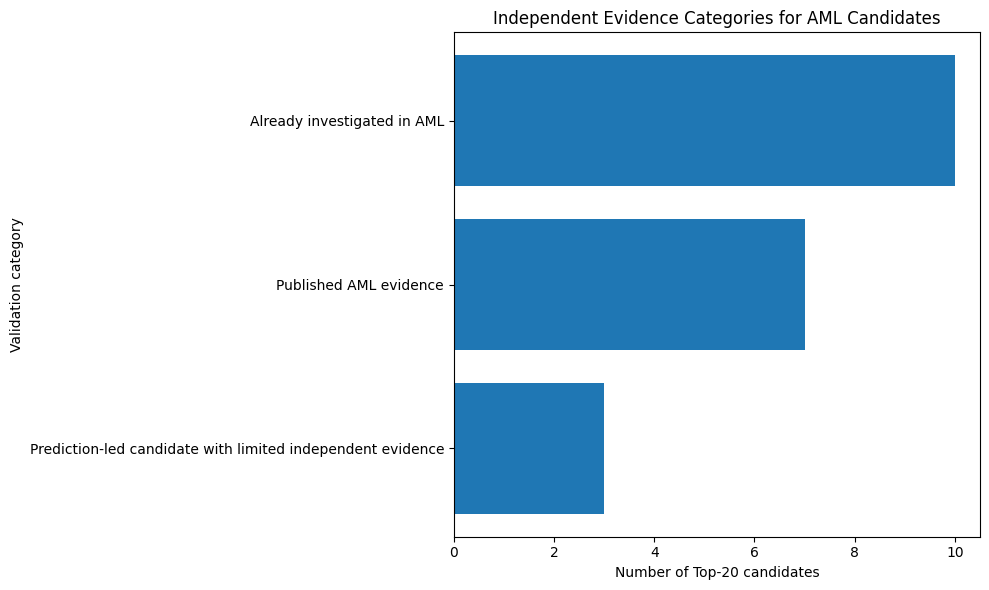

Figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/aml_candidate_validation_categories.png


In [33]:
category_counts = (
    validation_results_df[
        "validation_category"
    ]
    .value_counts()
    .sort_values()
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    category_counts.index,
    category_counts.values,
)

plt.xlabel(
    "Number of Top-20 candidates"
)

plt.ylabel(
    "Validation category"
)

plt.title(
    "Independent Evidence Categories for AML Candidates"
)

plt.tight_layout()

CATEGORY_FIGURE_PATH = (
    FIGURES_DIR
    / "aml_candidate_validation_categories.png"
)

plt.savefig(
    CATEGORY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    CATEGORY_FIGURE_PATH,
)

## 28. Candidate model scores with evidence category

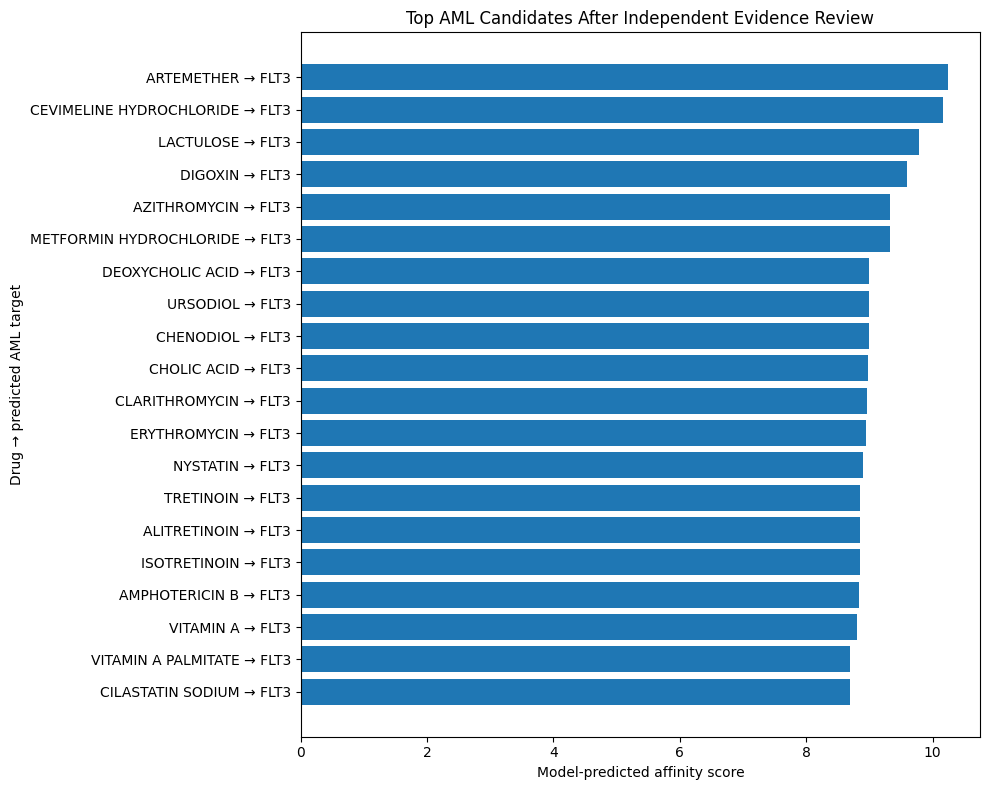

Figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/aml_validated_candidate_scores.png


In [34]:
score_column = (
    "mean_model_predicted_pkd"
    if "mean_model_predicted_pkd"
    in validation_results_df.columns
    else "advanced_predicted_pkd"
)

plot_df = (
    validation_results_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            score_column,
            "validation_category",
        ]
    ]
    .sort_values(
        score_column,
        ascending=True,
    )
)

plot_labels = (
    plot_df["drug_name"]
    + " → "
    + plot_df["paper_target"]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_labels,
    plot_df[
        score_column
    ],
)

plt.xlabel(
    "Model-predicted affinity score"
)

plt.ylabel(
    "Drug → predicted AML target"
)

plt.title(
    "Top AML Candidates After Independent Evidence Review"
)

plt.tight_layout()

SCORE_FIGURE_PATH = (
    FIGURES_DIR
    / "aml_validated_candidate_scores.png"
)

plt.savefig(
    SCORE_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    SCORE_FIGURE_PATH,
)

# Part K — Final validation summary



## 29. Evidence summary counts

In [35]:
validation_summary_df = pd.DataFrame(
    {
        "evidence": [
            "Top candidates reviewed",
            "ChEMBL target activity",
            "PubMed target literature",
            "PubMed AML literature",
            "AML clinical-trial records",
            "AML label signal",
            "Prediction-led limited-evidence candidates",
        ],
        "count": [
            len(
                validation_results_df
            ),
            int(
                validation_results_df[
                    "has_chembl_target_activity"
                ].sum()
            ),
            int(
                validation_results_df[
                    "has_pubmed_target_evidence"
                ].sum()
            ),
            int(
                validation_results_df[
                    "has_pubmed_aml_evidence"
                ].sum()
            ),
            int(
                validation_results_df[
                    "has_aml_clinical_trial"
                ].sum()
            ),
            int(
                validation_results_df[
                    "fda_aml_label_evidence"
                ].sum()
            ),
            len(
                prediction_led_df
            ),
        ],
    }
)

display(
    validation_summary_df
)

,evidence,count
0,Top candidates reviewed,20
1,ChEMBL target activity,0
2,PubMed target literature,5
3,PubMed AML literature,14
4,AML clinical-trial records,10
5,AML label signal,0
6,Prediction-led limited-evidence candidates,3


## 30. Final ranked interpretation

In [36]:



final_display_columns = [
    "candidate_rank",
    "drug_name",
    "paper_target",
    "validation_category",
    "interpretation_note",
]

display(
    validation_results_df[
        final_display_columns
    ]
    .sort_values(
        "candidate_rank"
    )
)

,candidate_rank,drug_name,paper_target,validation_category,interpretation_note
0,1,DIGOXIN,FLT3,Already investigated in AML,The candidate has been investigated in an AML-...
1,2,AZITHROMYCIN,FLT3,Published AML evidence,The drug has AML-related PubMed literature but...
2,3,CLARITHROMYCIN,FLT3,Already investigated in AML,The candidate has been investigated in an AML-...
3,4,ERYTHROMYCIN,FLT3,Already investigated in AML,The candidate has been investigated in an AML-...
4,5,DEOXYCHOLIC ACID,FLT3,Already investigated in AML,The candidate has been investigated in an AML-...
5,6,NYSTATIN,FLT3,Published AML evidence,The drug has AML-related PubMed literature but...
6,7,CHENODIOL,FLT3,Prediction-led candidate with limited independ...,The candidate is primarily model-driven in thi...
7,8,URSODIOL,FLT3,Published AML evidence,The drug has AML-related PubMed literature but...
8,9,CEVIMELINE HYDROCHLORIDE,FLT3,Prediction-led candidate with limited independ...,The candidate is primarily model-driven in thi...
9,10,AMPHOTERICIN B,FLT3,Already investigated in AML,The candidate has been investigated in an AML-...


## 31. Saved outputs

In [37]:
saved_outputs_df = pd.DataFrame(
    {
        "output": [
            "Validation input snapshot",
            "ChEMBL cache",
            "PubMed cache",
            "ClinicalTrials.gov cache",
            "openFDA label cache",
            "Full validation results",
            "Compact validation summary",
            "Candidates without AML label signal",
            "Prediction-led candidates",
            "Validation-category figure",
            "Candidate-score figure",
        ],
        "path": [
            VALIDATION_INPUT_PATH,
            CHEMBL_CACHE_PATH,
            PUBMED_CACHE_PATH,
            CLINICALTRIALS_CACHE_PATH,
            OPENFDA_CACHE_PATH,
            FULL_VALIDATION_PATH,
            COMPACT_VALIDATION_PATH,
            NON_LABEL_PATH,
            PREDICTION_LED_PATH,
            CATEGORY_FIGURE_PATH,
            SCORE_FIGURE_PATH,
        ],
    }
)

display(
    saved_outputs_df
)

,output,path
0,Validation input snapshot,/content/final-msc-dissertation-drug-repurposi...
1,ChEMBL cache,/content/final-msc-dissertation-drug-repurposi...
2,PubMed cache,/content/final-msc-dissertation-drug-repurposi...
3,ClinicalTrials.gov cache,/content/final-msc-dissertation-drug-repurposi...
4,openFDA label cache,/content/final-msc-dissertation-drug-repurposi...
5,Full validation results,/content/final-msc-dissertation-drug-repurposi...
6,Compact validation summary,/content/final-msc-dissertation-drug-repurposi...
7,Candidates without AML label signal,/content/final-msc-dissertation-drug-repurposi...
8,Prediction-led candidates,/content/final-msc-dissertation-drug-repurposi...
9,Validation-category figure,/content/final-msc-dissertation-drug-repurposi...


# Interpretation and limitations

This validation stage should be described as **external evidence checking**, not experimental validation.

Important limitations:

1. **Database presence is not proof of therapeutic efficacy.** ChEMBL activity, a PubMed article, or a registered clinical trial can provide supporting context but cannot confirm an AML treatment effect.
2. **Database absence is not proof of novelty.** Search terms, synonyms, indexing, older records, salts, combination therapies and database coverage can all cause relevant evidence to be missed.
3. **ClinicalTrials.gov records describe registered studies.** A matching study may be completed, terminated, ongoing or unsuccessful.
4. **openFDA label evidence is a screening signal.** Product labeling can change and openFDA itself notes that its reformatted labels should not be treated as a substitute for official medical or regulatory judgment.
5. **ChEMBL activity can come from different assays.** Kd, Ki, IC50 and EC50 values are not interchangeable, and the notebook therefore reports the evidence rather than converting them into a single experimental truth.
6. **PubMed counts are query-dependent.** Manual review of the most relevant papers is still required before making a biological claim about an individual candidate.
7. **The model was trained on DAVIS.** Predictions for targets far outside the kinase-heavy DAVIS domain require particular caution.
8. **The final candidates remain computational hypotheses.** Experimental binding assays and AML-relevant cellular or in-vivo studies would be necessary for biological validation.

For the dissertation, the strongest conclusion is therefore that this pipeline identifies and prioritises **computational repurposing hypotheses**, then places those predictions in the context of independent public evidence.

### Notebook completion

This notebook completes the full project workflow:

```text
DAVIS + KIBA benchmark data
          ↓
GCN / GAT / GIN baseline models
          ↓
Advanced GINE + frozen ESM-2
+ CNN + bidirectional cross-attention
          ↓
Random + cold-start evaluation
          ↓
Model comparison
          ↓
7 AML therapeutic targets
          ↓
FDA-approved small-molecule screen
          ↓
Top candidate rankings
          ↓
ChEMBL + PubMed + ClinicalTrials.gov + FDA label evidence
          ↓
Final evidence-aware AML repurposing hypotheses
```

The final validation tables can now be used directly in the dissertation Results and Discussion chapters, with individual high-priority candidates manually discussed using the linked PubMed, ChEMBL and clinical-trial records.